#Param Shah
##240905320
###Lab 11: SVM

## Question 1
Use the given code and modify for the IRIS dataset. Implement the SVM classifier in Python using scikit-learn. Apply the linear kernel function. Plot the scatter plot of the input features and the decision boundary.

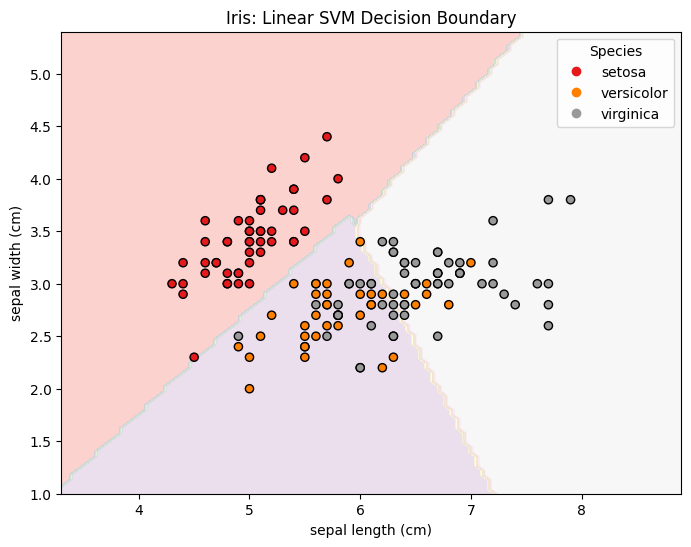

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay

iris = load_iris()
X = iris.data[:, :2]
y = iris.target
model = SVC(kernel="linear", C=1.0)
model.fit(X, y)
fig, ax = plt.subplots(figsize=(8, 6))
DecisionBoundaryDisplay.from_estimator(model, X, response_method="predict", cmap=plt.cm.Pastel1, alpha=0.6, ax=ax)
scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Set1, edgecolors="k", s=35)
ax.set(xlabel=iris.feature_names[0], ylabel=iris.feature_names[1], title="Iris: Linear SVM Decision Boundary")
ax.legend(scatter.legend_elements()[0], iris.target_names, title="Species")
plt.show()

## Question 2
Construct a simple SVM classifier that separates the two classes:

- Positively labeled points: (4, 1), (4, -1), (6, 0)
- Negatively labeled points: (1, 0), (0, 1), (0, -1)

Use +1 for positive and −1 for negative points. Implement a Python program using scikit-learn to draw the separating hyperplane and plot the input features.

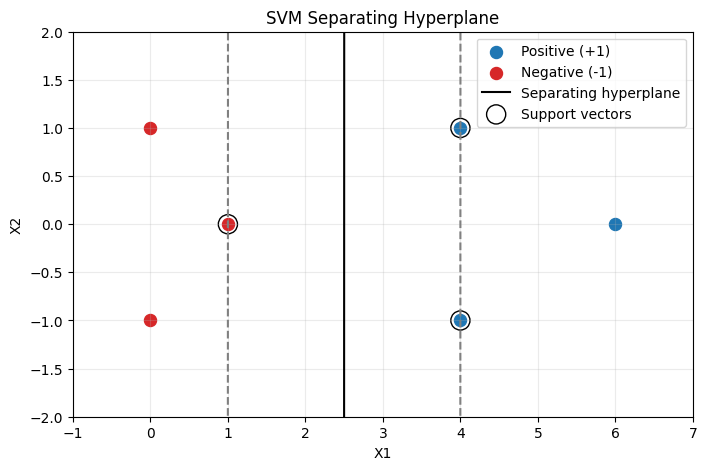

Weights: [ 6.6675e-01 -2.5000e-04] Intercept: -1.6669166666666666


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

X = np.array([[4, 1], [4, -1], [6, 0], [1, 0], [0, 1], [0, -1]], dtype=float)
y = np.array([1, 1, 1, -1, -1, -1])
model = SVC(kernel="linear", C=1e6)
model.fit(X, y)
w = model.coef_[0]
b = model.intercept_[0]
xx = np.linspace(-1, 7, 300)
line = -(w[0] * xx + b) / w[1] if abs(w[1]) > 1e-10 else None
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:blue", label="Positive (+1)", s=75)
ax.scatter(X[y == -1, 0], X[y == -1, 1], c="tab:red", label="Negative (-1)", s=75)
if line is None:
    ax.axvline(-b / w[0], color="black", label="Separating hyperplane")
    ax.axvline((-b + 1) / w[0], color="gray", linestyle="--")
    ax.axvline((-b - 1) / w[0], color="gray", linestyle="--")
else:
    ax.plot(xx, line, color="black", label="Separating hyperplane")
    ax.plot(xx, -(w[0] * xx + b - 1) / w[1], "--", color="gray")
    ax.plot(xx, -(w[0] * xx + b + 1) / w[1], "--", color="gray")
ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=190, facecolors="none", edgecolors="black", label="Support vectors")
ax.set(xlim=(-1, 7), ylim=(-2, 2), xlabel="X1", ylabel="X2", title="SVM Separating Hyperplane")
ax.legend()
ax.grid(alpha=0.25)
plt.show()
print("Weights:", w, "Intercept:", b)

## Question 3
Solve Question 2 manually in the observation book and implement the classifier **without using scikit-learn**.

For these points, the maximum-margin boundary is **x₁ = 2.5**. In the canonical SVM form, **w = (2/3, 0)** and **b = −5/3**, giving margin boundaries x₁ = 1 and x₁ = 4. The geometric distance from the decision boundary to either margin is 1.5.

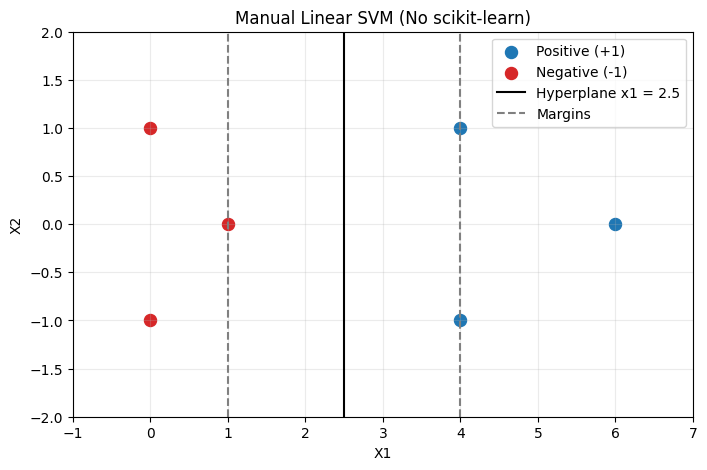

Predicted labels: [ 1  1  1 -1 -1 -1]
Accuracy: 1.0
Hyperplane: x1 = 2.5000000000000004


In [3]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([[4, 1], [4, -1], [6, 0], [1, 0], [0, 1], [0, -1]], dtype=float)
y = np.array([1, 1, 1, -1, -1, -1])
w = np.array([2 / 3, 0.0])
b = -5 / 3
predicted = np.where(X @ w + b >= 0, 1, -1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:blue", s=75, label="Positive (+1)")
ax.scatter(X[y == -1, 0], X[y == -1, 1], c="tab:red", s=75, label="Negative (-1)")
ax.axvline(-b / w[0], color="black", label="Hyperplane x1 = 2.5")
ax.axvline((-b - 1) / w[0], color="gray", linestyle="--", label="Margins")
ax.axvline((-b + 1) / w[0], color="gray", linestyle="--")
ax.set(xlim=(-1, 7), ylim=(-2, 2), xlabel="X1", ylabel="X2", title="Manual Linear SVM (No scikit-learn)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()
print("Predicted labels:", predicted)
print("Accuracy:", np.mean(predicted == y))
print("Hyperplane: x1 =", -b / w[0])

## Question 4
Sketch the hyperplane **1 + 2X₁ + 3X₂ = 0** without scikit-learn. Indicate points where **1 + 3X₁ − X₂** is positive, negative, or zero, for x₁, x₂ ∈ (−10, 10) at increments of 1. Find the slope and intercept and compare with manual results.

Rearranging the hyperplane gives **X₂ = −(2/3)X₁ − 1/3**, so the slope is **−2/3** and the intercept is **−1/3**. The sign classification uses the *different* expression specified in the question.

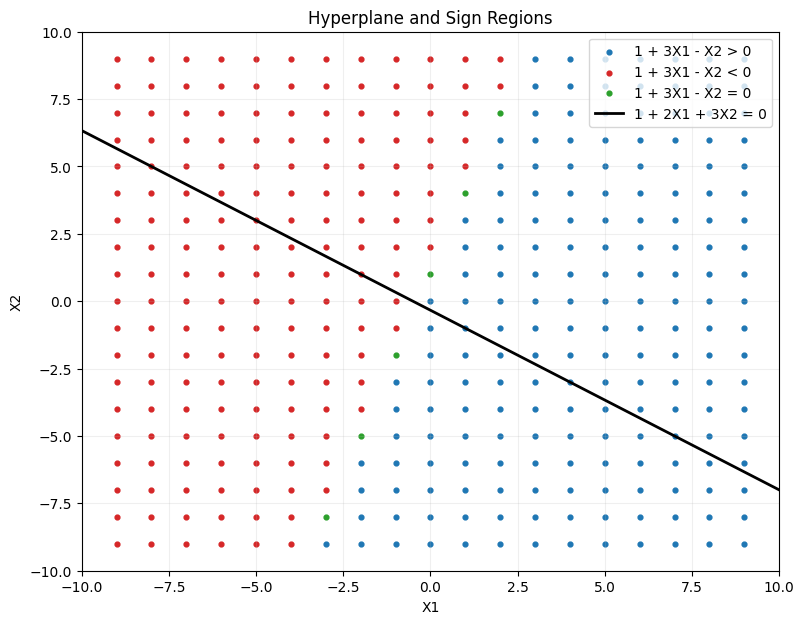

Slope: -0.6666666666666666
Y-intercept: -0.3333333333333333


In [4]:
import numpy as np
import matplotlib.pyplot as plt

values = np.arange(-9, 10, 1)
x1, x2 = np.meshgrid(values, values)
score = 1 + 3 * x1 - x2
xx = np.linspace(-10, 10, 400)
fig, ax = plt.subplots(figsize=(9, 7))
for condition, color, label in [(score > 0, "tab:blue", "1 + 3X1 - X2 > 0"), (score < 0, "tab:red", "1 + 3X1 - X2 < 0"), (score == 0, "tab:green", "1 + 3X1 - X2 = 0")]:
    ax.scatter(x1[condition], x2[condition], s=12, color=color, label=label)
ax.plot(xx, -(1 + 2 * xx) / 3, color="black", linewidth=2, label="1 + 2X1 + 3X2 = 0")
ax.set(xlim=(-10, 10), ylim=(-10, 10), xlabel="X1", ylabel="X2", title="Hyperplane and Sign Regions")
ax.grid(alpha=0.2)
ax.legend(loc="upper right")
plt.show()
print("Slope:", -2 / 3)
print("Y-intercept:", -1 / 3)

## Question 5
Given two hyperplanes for SVM classifier 1 and classifier 2, identify the best hyperplane:

- **Classifier 1:** 5 + 2x₁ + 5x₂ = 0
- **Classifier 2:** 5 + 20x₁ + 50x₂ = 0

Without scikit-learn, draw both hyperplanes and show points for which each expression is positive, negative, or zero. Find slope and intercept and compare with manual results.

**Note:** The exercise does not supply labeled training points, so the best *classifier* cannot be established from classification accuracy or maximum margin on data. The plots use an illustrative integer grid, not a supplied dataset. The two lines are parallel; their slopes are equal, but their intercepts differ.

Classifier 1: slope = -0.400, intercept = -1.000
Classifier 2: slope = -0.400, intercept = -0.100


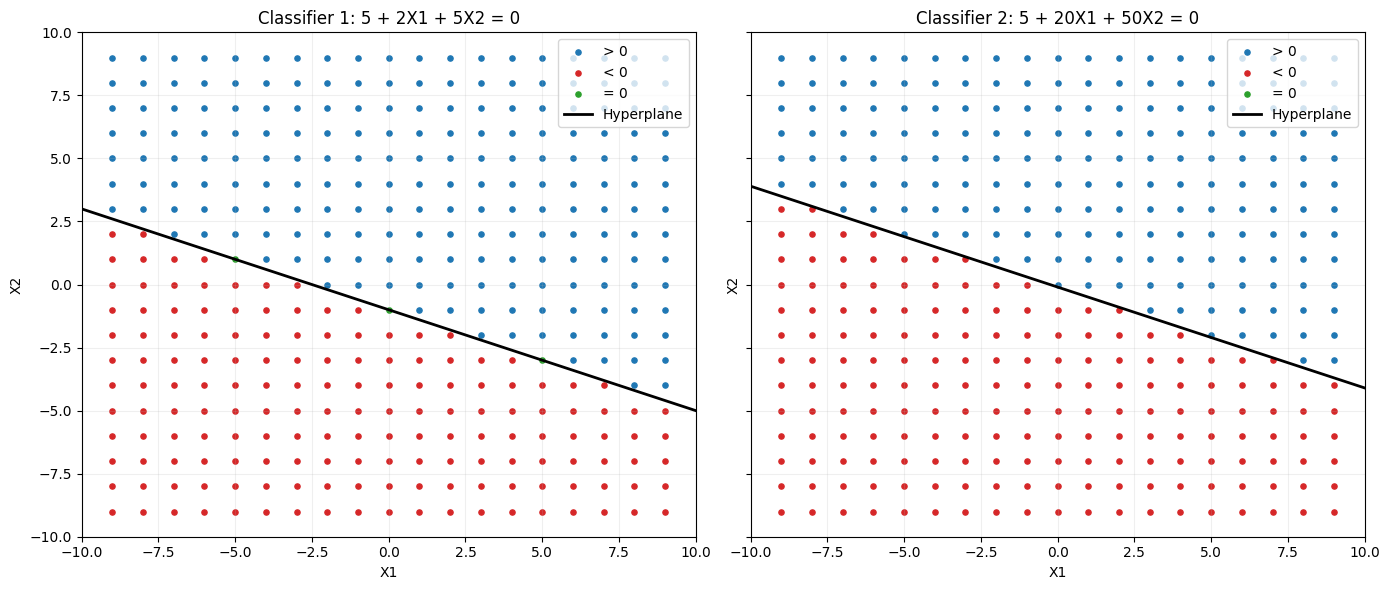

A best classifier cannot be determined without labeled sample data or an explicit selection criterion.


In [5]:
import numpy as np
import matplotlib.pyplot as plt

values = np.arange(-9, 10)
x1, x2 = np.meshgrid(values, values)
xx = np.linspace(-10, 10, 400)
functions = [(5, 2, 5), (5, 20, 50)]
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for index, ((b, w1, w2), ax) in enumerate(zip(functions, axes), start=1):
    score = b + w1 * x1 + w2 * x2
    for condition, color, label in [(score > 0, "tab:blue", "> 0"), (score < 0, "tab:red", "< 0"), (np.isclose(score, 0), "tab:green", "= 0")]:
        ax.scatter(x1[condition], x2[condition], color=color, s=14, label=label)
    ax.plot(xx, -(b + w1 * xx) / w2, color="black", linewidth=2, label="Hyperplane")
    ax.set(xlim=(-10, 10), ylim=(-10, 10), xlabel="X1", ylabel="X2", title=f"Classifier {index}: {b} + {w1}X1 + {w2}X2 = 0")
    ax.grid(alpha=0.2)
    ax.legend()
    print(f"Classifier {index}: slope = {-w1 / w2:.3f}, intercept = {-b / w2:.3f}")
axes[0].set_ylabel("X2")
plt.tight_layout()
plt.show()
print("A best classifier cannot be determined without labeled sample data or an explicit selection criterion.")